# Showing differences in pooled vs. interacted mortality models
At, say, GWL 2
| Mean change | Mean change | 
| Dom unc     | dom unc     |

In [15]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import warnings
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
import matplotlib as mpl
from matplotlib import patches as mpatches
from cartopy import crs as ccrs
import cmocean

from funcs_support import get_filepaths,get_params,utility_print,load_shp
from funcs_readregs import coeffs_mortality,coeffs_gdppc,coeffs_payroll
from funcs_plot import plot_map,vals_to_color_triangle,add_colorbar
dir_list = get_params()

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


In [2]:
# Get filenames of impact projections
fns = get_filepaths(source_dir = 'impacts',dir_list = {'impacts':dir_list['proc']+'impact_projs/'})
fns = fns.query('freq == "agg"')
fns = fns.iloc[['crossfit' not in var for var in fns.varname.values]]
fns = fns.set_index(['varname','model']).sort_index()

In [3]:
gdf = load_shp('mortality')

### Example damage functions

In [4]:
reg_data = pd.read_csv(dir_list['proc']+'reg_inputs/mortality/reginputs_mortality_1deg.csv',low_memory=False,index_col=0)
reg_data = reg_data.query('iso != "IND"')
insamp_meanT = (reg_data.lr_tavg_insamp*reg_data.population).sum()/reg_data.population.sum()
insamp_meanG = (reg_data.loggdppc_adm1_avg*reg_data.population).sum()/reg_data.population.sum()
print(f'mean T in sample: {str(insamp_meanT)}')
print(f'mean GDP pc in sample: {str(np.exp(insamp_meanG))}')

mean T in sample: 13.726480045371737
mean GDP pc in sample: 19615.417911957586


In [5]:
samp_preds = reg_data.query('year >= 1980 & year <= 2010 and agegroup == "total"').groupby(['adm0','adm1_id'])[['lr_tavg_insamp','loggdppc_adm1_avg','population']].mean()
samp_preds = samp_preds.rename({'lr_tavg_insamp':'lrtavg',
                                  'loggdppc_adm1_avg':'lgdppc',
                                  'population':'pop'},axis=1)
samp_preds = samp_preds.to_xarray().stack(locv = ['adm0','adm1_id']).dropna('locv',how='all')
samp_preds = xr.merge([xr.concat([xr.ones_like(samp_preds.lrtavg),
           samp_preds['lgdppc'],
           samp_preds['lrtavg']],
          dim=pd.Index(['1','lgdppc','lrtavg'],name='covar')).to_dataset(name='covars'),
          samp_preds.pop])

In [6]:
# Load covariates
preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
preds_sub = preds.sel(pred_ssp='ssp3',pred_model='low',ageset='agetotal').mean('year')
impreg_meanT = ((preds_sub.lrtavg.mean(('proj_base','idv'))*preds_sub.pop).sum('hierid')/preds_sub.pop.sum('hierid')).compute()
impreg_meanG = ((preds_sub.lgdppc*preds_sub.pop).sum('hierid')/preds_sub.pop.sum('hierid')).compute()

print(f'mean T in impact-region (historically): {str(impreg_meanT.values)}')
print(f'mean GDP pc in impact-region (historically): {str(np.exp(impreg_meanG.values))}')

mean T in impact-region (historically): [19.15456679 19.59863687 20.60372531 21.66925885 22.66161988 23.44635161
 24.10471475 24.71857094]
mean GDP pc in impact-region (historically): [ 5524.14054281  5940.48067967  9238.51118763 10906.93142805
 11248.2569978  11277.07900238 11291.76787259 11300.97538402]


In [7]:
impreg_preds = preds.sel(pred_ssp='ssp3',pred_model='high',ageset='agetotal').mean(['year','idv'])
impreg_preds = impreg_preds[['lrtavg','lgdppc','pop']]
impreg_preds = xr.merge([xr.concat([xr.ones_like(impreg_preds.lrtavg),
           impreg_preds['lgdppc'].expand_dims({'proj_base':impreg_preds.proj_base}),
           impreg_preds['lrtavg']],
          dim=pd.Index(['1','lgdppc','lrtavg'],
                       name='covar'),
                      compat='no_conflicts').to_dataset(name='covars'),
          impreg_preds.pop],compat='no_conflicts').load()


In [8]:
# Load interacted coefficients
coeffs_int,vcv_int = coeffs_mortality(spec='interacted')

# Load base coefficients
coeffs_base,vcv_base = coeffs_mortality()

# Get temperature to feed damage function
Ts = xr.Dataset(coords = {'tas':(['tas'],np.arange(-20,50))})
Ts['tassumpoly'] = xr.concat([Ts.tas**k for k in np.arange(1,5)],
                             dim=pd.Index([f'tassumpoly_{k}' for k in np.arange(1,5)],name='pred'))

In [9]:
dmgfs = xr.concat([((coeffs_int.sel(ageset='agetotal')*samp_preds.covars*Ts.tassumpoly).sum(('pred','covar'),skipna=False).weighted(samp_preds.pop).mean('locv')),
                   ((coeffs_int.sel(ageset='agetotal')*impreg_preds.sel(gwl=0.61,drop=True).covars*Ts.tassumpoly).sum(('pred','covar'),skipna=False).weighted(impreg_preds.sel(gwl=0.61,drop=True).pop).mean('hierid')),
                   ((coeffs_int.sel(ageset='agetotal')*impreg_preds.sel(gwl=2,drop=True).covars*Ts.tassumpoly).sum(('pred','covar'),skipna=False).weighted(impreg_preds.sel(gwl=2,drop=True).pop).mean('hierid'))],
                  dim=pd.Index(['Reg. input mean GDP, T','GWL0.61 mean GDP, T', 'GWL2 mean GDP, T'],name='sample'))
dmgfs = dmgfs - dmgfs.sel(tas=slice(10,30)).min('tas')

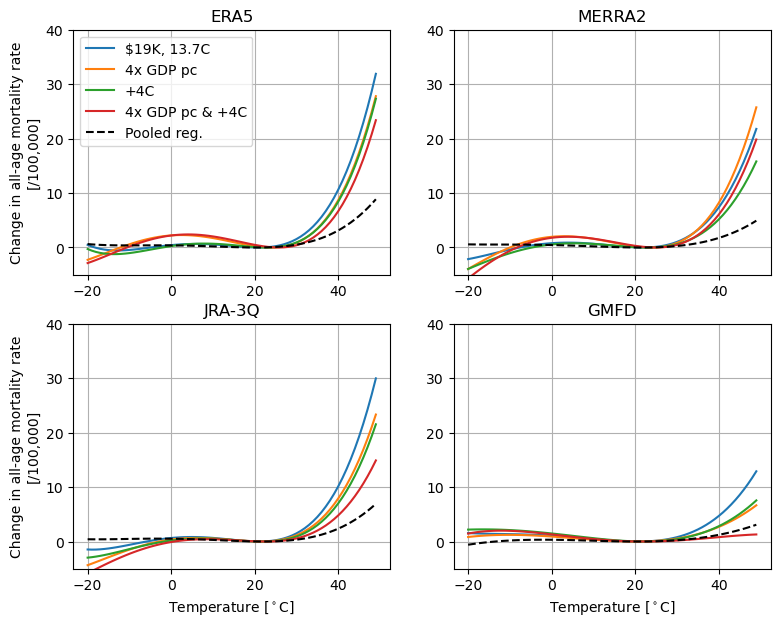

In [10]:
fig = plt.figure(figsize=(9,7))

#refT = 17 # ~T of avg. impact region
#refG = 7500  # ~GDP per cap of avg. impact region

refT = np.round(insamp_meanT,1) # ~T of avg. forcing dataset region
refG = np.exp(insamp_meanG) # ~GDP per cap of avg. forcing dataset region

#refT = np.round(impreg_meanT,1) # ~T of avg. impact region
#refG = np.exp(impreg_meanG) # ~GDP per cap of avg. impact region

for plt_idx,pb in enumerate(['ERA5','MERRA2','JRA-3Q','GMFD']):
    sp = {'ageset':'agetotal','proj_base':pb}
    coeffs_tmp = coeffs_int.sel(sp)

    preds_tmp = xr.DataArray([[1,np.log(refG),refT],
                           [1,np.log(refG*4),refT],
                           [1,np.log(refG),refT+4],
                           [1,np.log(refG*4),refT+4]],
                          dims = ['sample','covar'],
                          coords = {'covar':(['covar'],['1','lgdppc','lrtavg']),
                                    'sample':(['sample'],[f'${str(int(refG/1000))}K, {str(refT)}C','4x GDP pc','+4C','4x GDP pc & +4C'])})
    
    ax = plt.subplot(2,2,plt_idx+1)
    dmgf = (coeffs_tmp*preds_tmp*Ts.tassumpoly).sum(('pred','covar'))
    dmgf = dmgf - dmgf.sel(tas=slice(10,30)).min('tas')
    for smpl in dmgf.sample.values:
        dmgf.sel(sample=smpl).coeffs.plot(label=smpl)

    coeffs_tmp_base = coeffs_base.sel(proj_base = pb)
    dmgf_base = (coeffs_tmp_base*Ts.tassumpoly).sum('pred')
    dmgf_base = dmgf_base - dmgf_base.sel(tas=slice(10,30)).min('tas')
    dmgf_base.coeffs.plot(color='k',linestyle='--',label='Pooled reg.')
    
    
    ax.set_ylim([-5,40])
    ax.grid(which='both')
    
    if plt_idx == 0:
        ax.legend()
    
    ax.set_title(pb)

    if plt_idx < 2:
        ax.set_xlabel('')
    else:
        ax.set_xlabel(r'Temperature [$^\circ$C]')
    if plt_idx in [0,2]:
        ax.set_ylabel('Change in all-age mortality rate\n[/100,000]')
    else:
        ax.set_ylabel('')


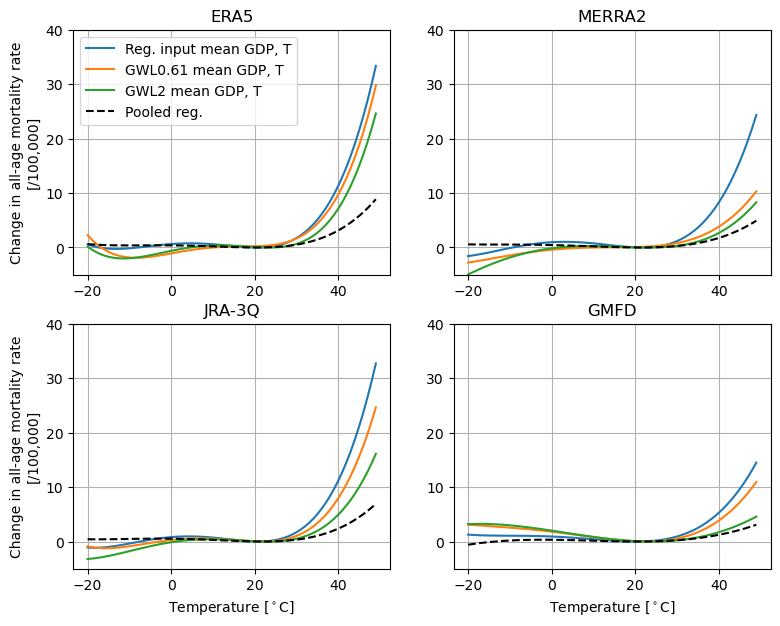

In [11]:
fig = plt.figure(figsize=(9,7))

for plt_idx,pb in enumerate(['ERA5','MERRA2','JRA-3Q','GMFD']):
    sp = {'ageset':'agetotal','proj_base':pb}
    coeffs_tmp = coeffs_int.sel(sp)

    preds_tmp = xr.DataArray([[1,insamp_meanG,insamp_meanT],
                           [1,impreg_meanG.sel(gwl=0.61),impreg_meanT.sel(gwl=0.61)],
                           [1,impreg_meanG.sel(gwl=2),impreg_meanT.sel(gwl=2)]],
                          dims = ['sample','covar'],
                          coords = {'covar':(['covar'],['1','lgdppc','lrtavg']),
                                    'sample':(['sample'],[f'In-sample fit GDP, T','Imp. region, GWL0.61 GDP pc, T','Imp.region, GWL2 GDP pc, T'])})
    
    ax = plt.subplot(2,2,plt_idx+1)
    #dmgf = (coeffs_tmp*preds_tmp*Ts.tassumpoly).sum(('pred','covar'))
    #dmgf = dmgf - dmgf.sel(tas=slice(10,30)).min('tas')
    for smpl in dmgfs.sample.values:
        dmgfs.sel(sample=smpl,proj_base = pb).coeffs.plot(label=smpl)

    coeffs_tmp_base = coeffs_base.sel(proj_base = pb)
    dmgf_base = (coeffs_tmp_base*Ts.tassumpoly).sum('pred')
    dmgf_base = dmgf_base - dmgf_base.sel(tas=slice(10,30)).min('tas')
    dmgf_base.coeffs.plot(color='k',linestyle='--',label='Pooled reg.')
    
    
    ax.set_ylim([-5,40])
    ax.grid(which='both')
    
    if plt_idx == 0:
        ax.legend()
    
    ax.set_title(pb)

    if plt_idx < 2:
        ax.set_xlabel('')
    else:
        ax.set_xlabel(r'Temperature [$^\circ$C]')
    if plt_idx in [0,2]:
        ax.set_ylabel('Change in all-age mortality rate\n[/100,000]')
    else:
        ax.set_ylabel('')


### Uncertainty partitioning maps

In [12]:

params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'mortality-interacted':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

imp_params = {'dmortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'dmortality-interacted':{'pred_ssp':'ssp3','pred_model':'high','ageset':'agetotal'},
              'dgdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'dpayroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}


idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}


nruns = {'dmortality':13,
         'dmortality-interacted':13,
         'dgdppc':13,
         'dpayroll':10}

cbar_params = {'dmortality':{'vmin':-100,'vmax':100,'cmap':cmocean.cm.balance},
             'dmortality-interacted':{'vmin':-100,'vmax':100,'cmap':cmocean.cm.balance}}

uncert_typ = {'mortality':'13runs8mods',
              'mortality-interacted':'13runs8mods'}

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_59613/2414470614.py:72: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss['dmortality-interacted'] = dss['dmortality'] - dss['dmortality_ref']


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/pooled_v_interacted.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/pooled_v_interacted.png saved!


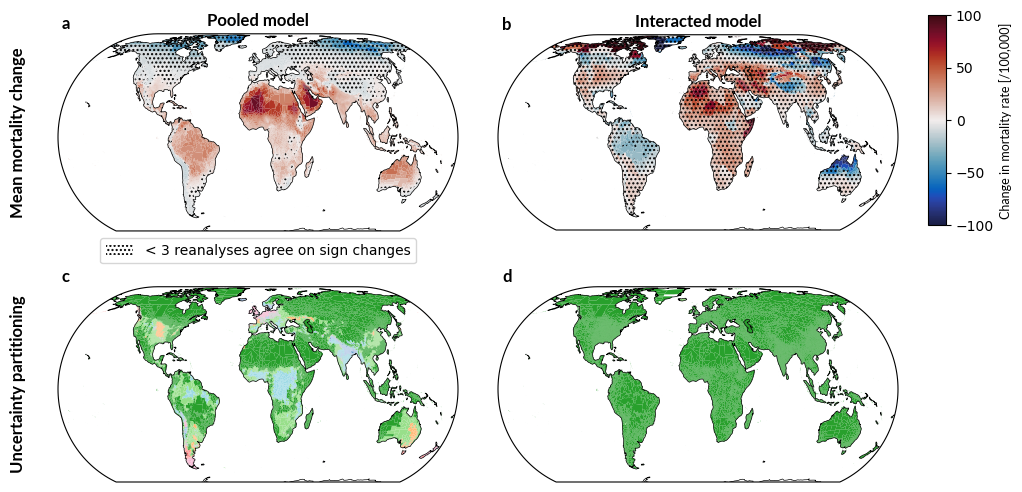

In [19]:
gwl = 2
keep_idvs_ref_gwl = 2

save_fig = True
output_fn = dir_list['figs']+'extra_figs/pooled_v_interacted'

fig = plt.figure(figsize=(12,6))
gs = plt.GridSpec(nrows=len(params_proc),
                  ncols=3*4)

proj = ccrs.EckertIV()

titles = {'dmortality':'Pooled model',
          'dmortality-interacted':'Interacted model'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}


for col_idx,var in enumerate(['dmortality','dmortality-interacted']):
    proc = re.sub(r'^d','',var)

    #-------------------------------
    # Load corresponding shapefile -
    #-------------------------------
    # Load shapefile
    gpd = load_shp('mortality')

    #------------------------------------------
    # Plot mean changes -----------------------
    #---------------------------
    # Load impact data ---------
    #---------------------------
    dss = []
    for row in fns.loc[var].iterrows():
        with warnings.catch_warnings():
            # .done flag warning in zarr opening
            warnings.filterwarnings('ignore')
            ds_tmp = xr.open_zarr(row[1]['path'],consolidated=False)
        if ds_tmp.sizes['idv'] < nruns[var]:
            continue
        else:
            ds_tmp = ds_tmp.sel(imp_params[var],drop=True)
            
            # Drop all-na idvs
            keep_idvs = ds_tmp.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv
            ds_tmp = ds_tmp.sel(idv = keep_idvs.values)
            # Get the first x runs
            ds_tmp = ds_tmp.isel(idv = slice(0,nruns[var]))
    
            if ds_tmp.sizes['idv']<nruns[var]:
                continue
            
            # Get mean over different obs products
            #ds_tmp = ds_tmp.mean(('proj_base'))
            ds_tmp['exprun'] = ds_tmp['experiment'].load()+ds_tmp['run'].load()
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        
            dss.append(ds_tmp)
            
    # Concat
    dss = xr.concat(dss,
                    dim='idv',
                    join='outer',
                    data_vars='minimal').load()

    # For interacted, the signal is the difference between 
    # "dmortality" (assuming climate + society changing) and
    # "dmortality_ref" (assuming climate constant, society changing)
    if proc == 'mortality-interacted':
        dss['dmortality-interacted'] = dss['dmortality'] - dss['dmortality_ref']
        dss = dss.drop_vars(['dmortality','dmortality_ref'])
    
    dss['poly_idx'] = dss['locid']
    dss = dss.drop_vars('locid').rename({'poly_idx':'locid'})
    
    # Plot ---------
    ax_map = plt.subplot(2,2,col_idx+1,projection=proj)

    plot_data = dss[var].sel(gwl=gwl).mean(('proj_base','idv'))

    fig,ax = plot_map(plot_data.sel(locid = gdf.locid.values),
             gdf,**cbar_params[var],fig=fig,ax=ax_map)
    ax.coastlines(linewidth=0.5)

    ax.set_title(titles[var],font=extra_fonts['lato-bold'],fontsize=12)

    # Get regions where less than 3 proj_base means 
    # have the same sign 
    min_sign_agree = 3
    hatch_regs = np.abs((dss.sel(gwl=gwl).mean('idv')/np.abs(dss.sel(gwl=gwl).mean('idv'))).sum('proj_base')[var])<min_sign_agree
    
    gdf_hatch = gdf.set_index('locid').join(hatch_regs.to_dataframe()[['d'+proc]])
    gdf_hatch = gdf_hatch.where(gdf_hatch['d'+proc]).dropna(how='all').dissolve()
    
    gdf_hatch.plot(hatch='....',facecolor='none',linewidth=0,ax=ax,transform=ccrs.PlateCarree())

    if col_idx == 0:
        label = '< 3 reanalyses agree on sign changes'
        ax.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                                   hatch='....', label=label)],
                          bbox_to_anchor = [0.5,-0.2],loc='lower center')
    
        ax.annotate('Mean mortality change',(-0.1,0.5),xycoords = 'axes fraction',
                    rotation=90,ha='center',va='center',
                font=extra_fonts['lato-bold'],fontsize=12)

    # Subplot label
    ax.annotate(string.ascii_lowercase[col_idx],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])


    if col_idx == 1:
        # Horizontal colorbar
        fig.subplots_adjust(right=0.825,wspace=0.1)
        cbar = add_colorbar(cbar_params[var],orientation='vertical',fig=fig,
                            axpos = [0.85, 0.55, 0.015, 0.35])
        cbar.set_label('Change in mortality rate [/100,000]',font = extra_fonts['lato'],fontsize=9)


    #------------------------------------------
    # Plot dom uncertainty --------------------
    #-------------------------------
    # Load partitioned uncertainty
    #-------------------------------
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[var])

    # Plot ---------
    ax_map = plt.subplot(2,2,2+col_idx+1,projection=proj)
    
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)

    # Subplot label
    ax_map.annotate(string.ascii_lowercase[col_idx+2],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])

    if col_idx == 0:
        ax_map.annotate('Uncertainty partitioning',(-0.1,0.5),xycoords = 'axes fraction',rotation=90,ha='center',va='center',
                font=extra_fonts['lato-bold'],fontsize=12)

if save_fig:
    utility_print(output_fn)
    